# [Atlas - 27 Tau](../../../Costellazioni/Taurus/Atlas.html) del [11/01/2026](../Index.html)

In [1]:
import math
import sys
sys.path.append('../../../src')
import spectrum as spec
import pandas as pd

## Camera Settings

- Gain=100
- Exposure=40.000s
- Brightness=5
- Temperature=-10
- StartCapture=2026-01-11T17:16:58.7753338Z
- EndCapture=2026-01-11T17:37:15.3957534Z






























## Raw Spectrum

Spettro ottenuto come media di 28 immagini. Applicati bias, dark e flat. Elaborazione con ISIS

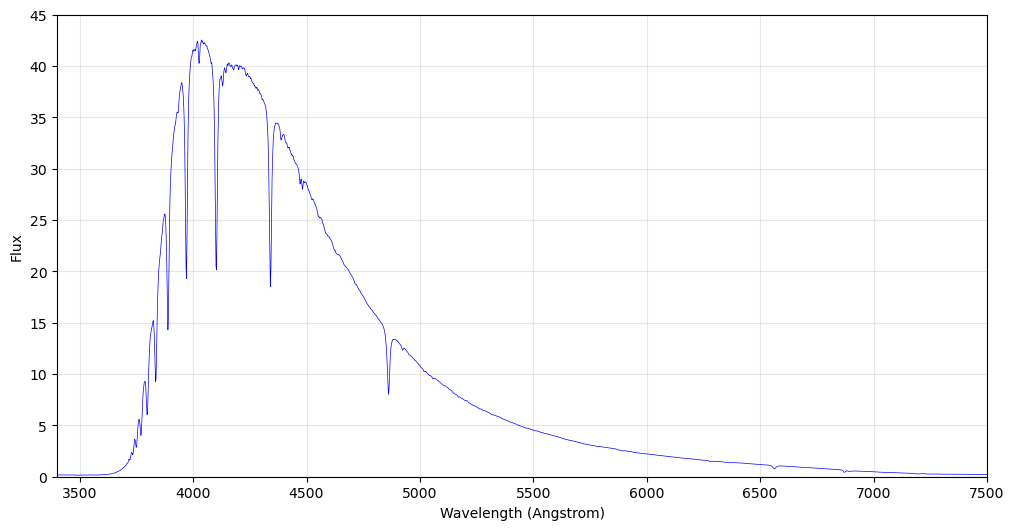

In [2]:
raw_wavelength, raw_flux = spec.load("_atlas_20260111_730.fit")
raw_flux = spec.cleanup_flux(raw_flux)
spec.simple_plot(raw_wavelength, raw_flux, wl_range = (3400, 7500), flux_range=(0.0,45.0))

## Rectified Spectrum

In [3]:
wavelength, flux = spec.load("_atlas_20260111_730-rect.fit")
flux = spec.cleanup_flux(flux)
print(f"SNR Reale stimato: {spec.calc_snr(wavelength, flux, 6730, 6830):.1f}")

SNR Reale stimato: 642.9


In [4]:
spectral_lines_summary = pd.read_csv('Atlas spec - Summary.csv', usecols=[0, 1, 2], names=["name","class","wavelength"])
spectral_lines_all = pd.read_csv('Atlas spec - 2026-01-11.csv', usecols=[0, 1, 2], names=["name","class","wavelength"])

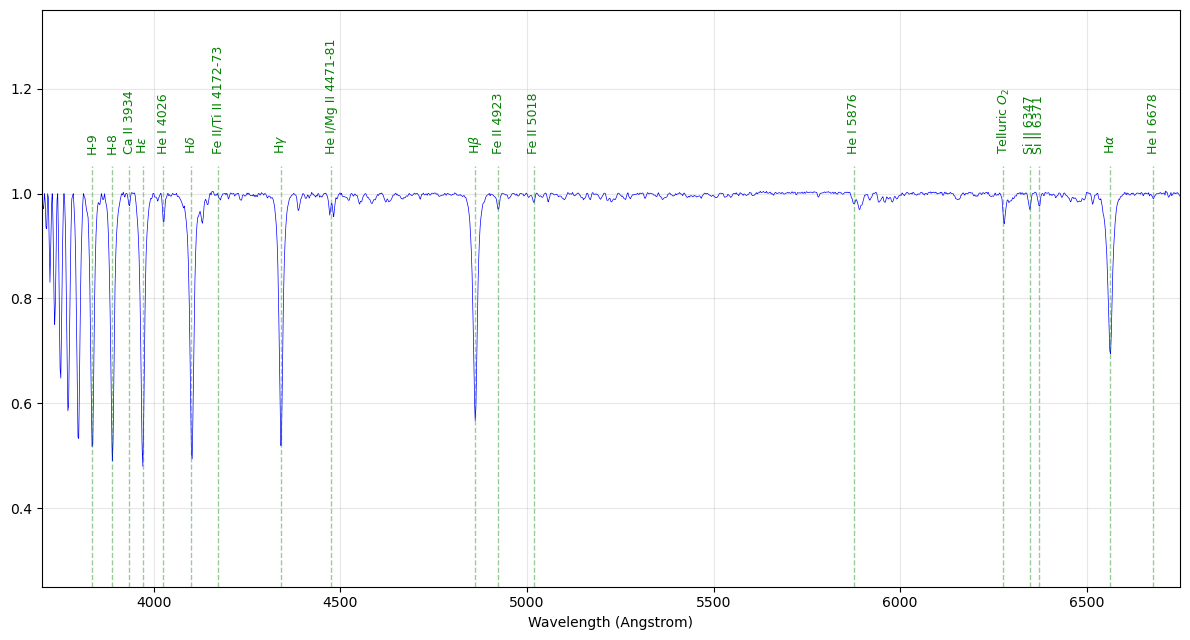

In [5]:
spec.plot_with_lines(wavelength, flux, spectral_lines_summary, (3700,6750), (0.25,1.35))

### Zoom  370 - 400 nm

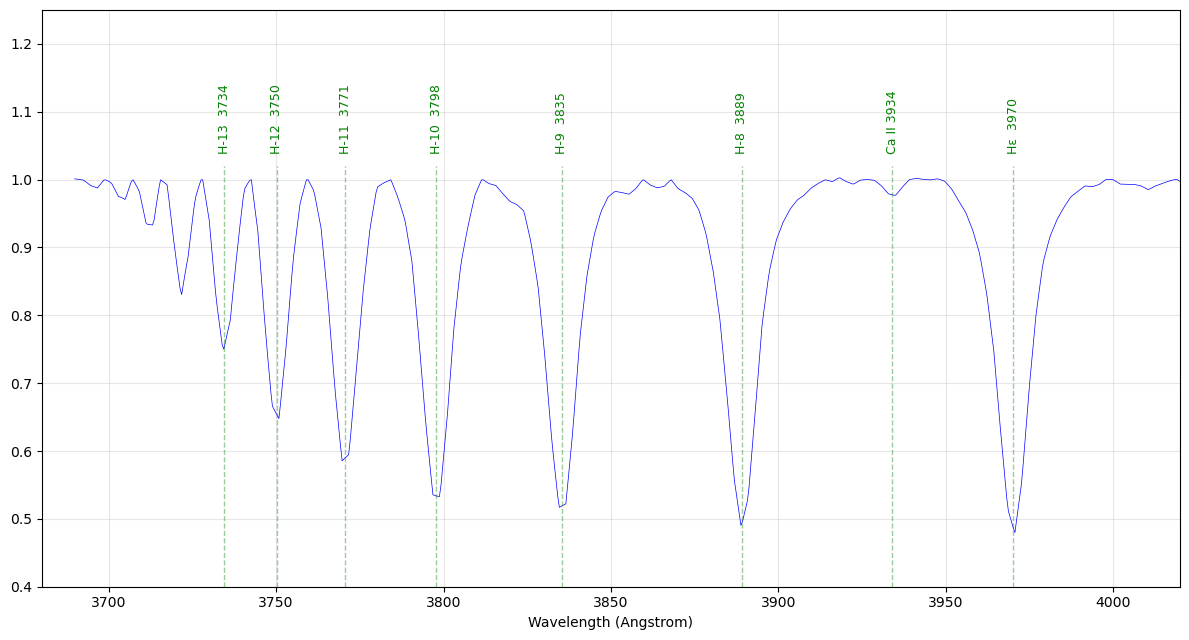

In [6]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (3680,4020), (0.40,1.25))

### Zoom  400 - 430 nm

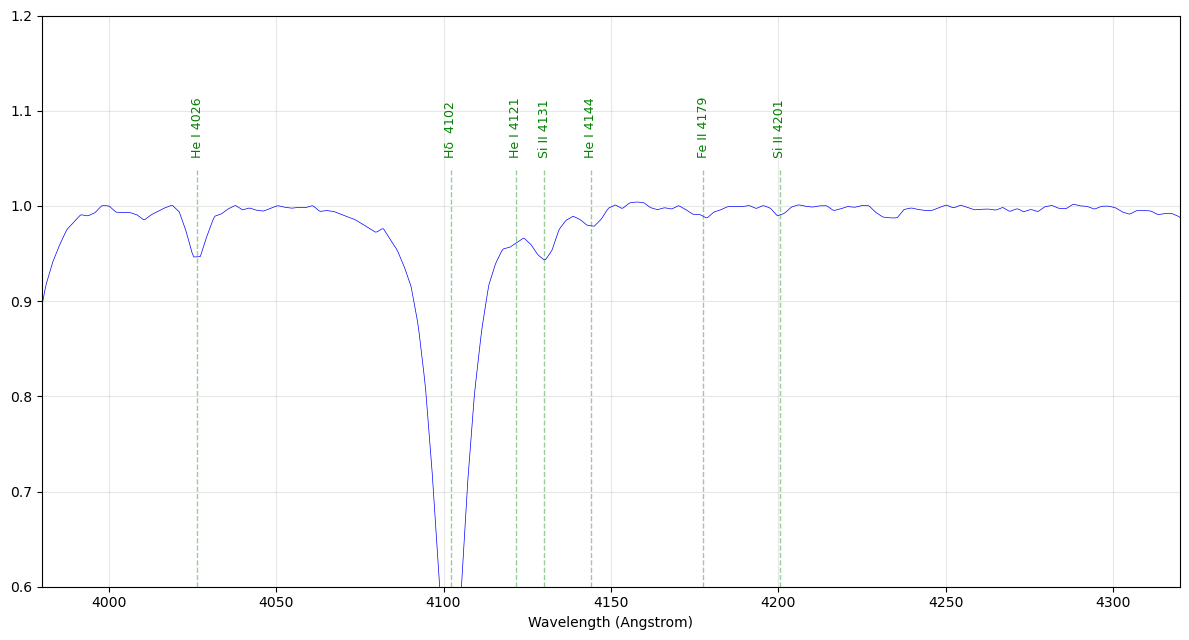

In [7]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (3980,4320), (0.60,1.20))

### Zoom 430 - 460 nm

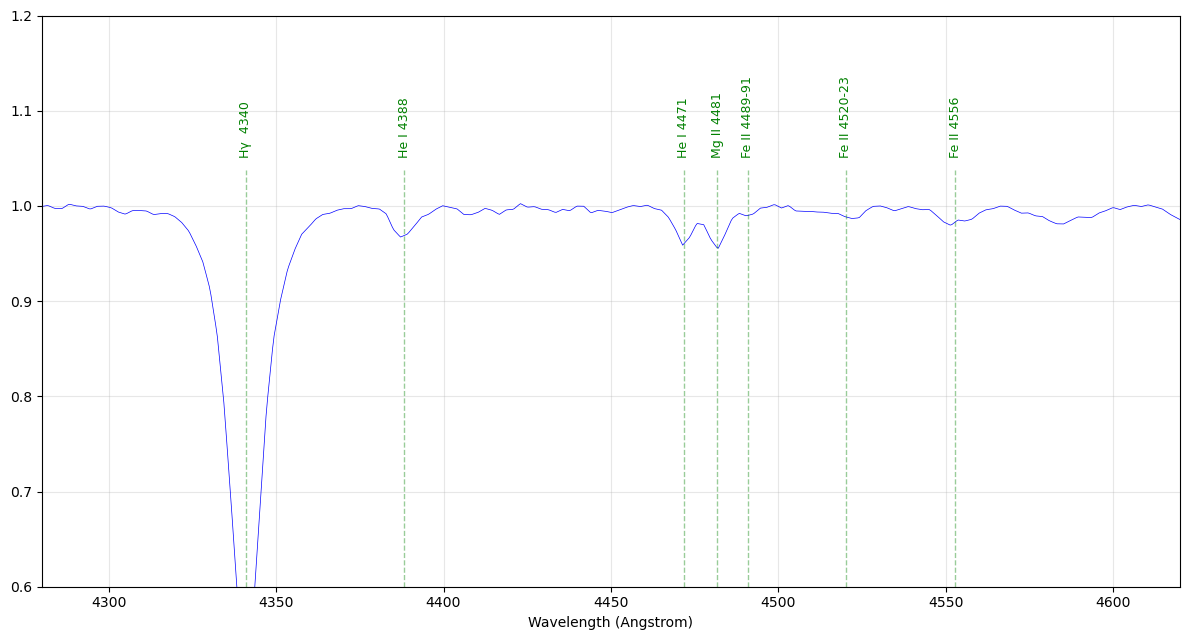

In [8]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4280,4620), (0.60,1.20))

### Zoom  460 - 490 nm

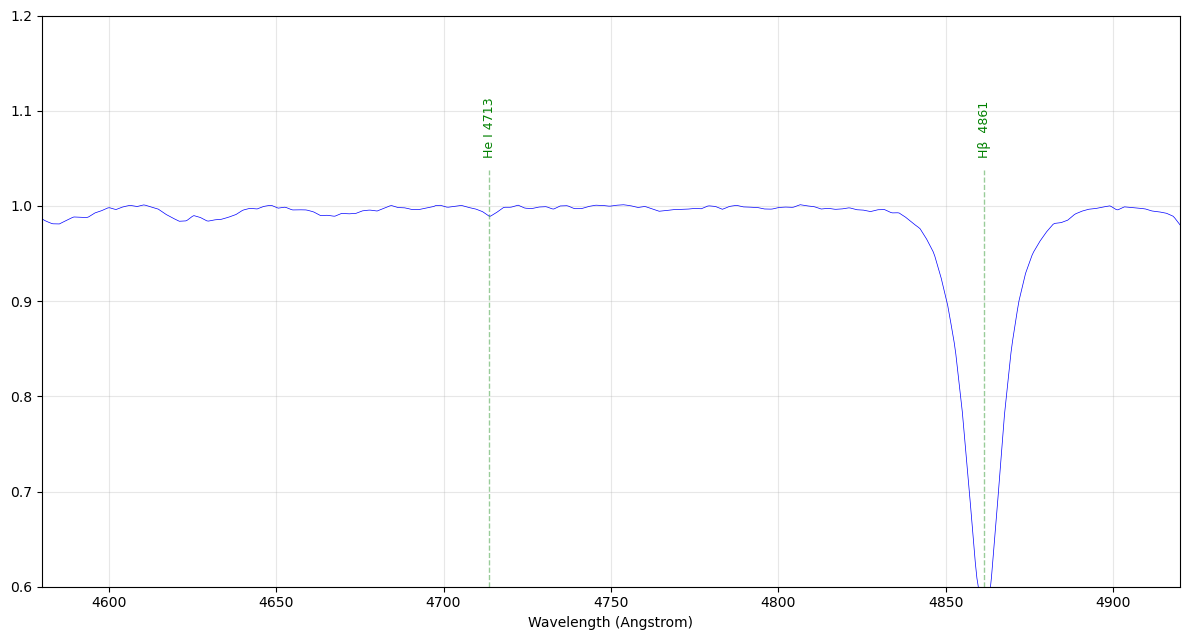

In [9]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4580,4920), (0.60,1.20))

### Zoom  490 - 540 nm

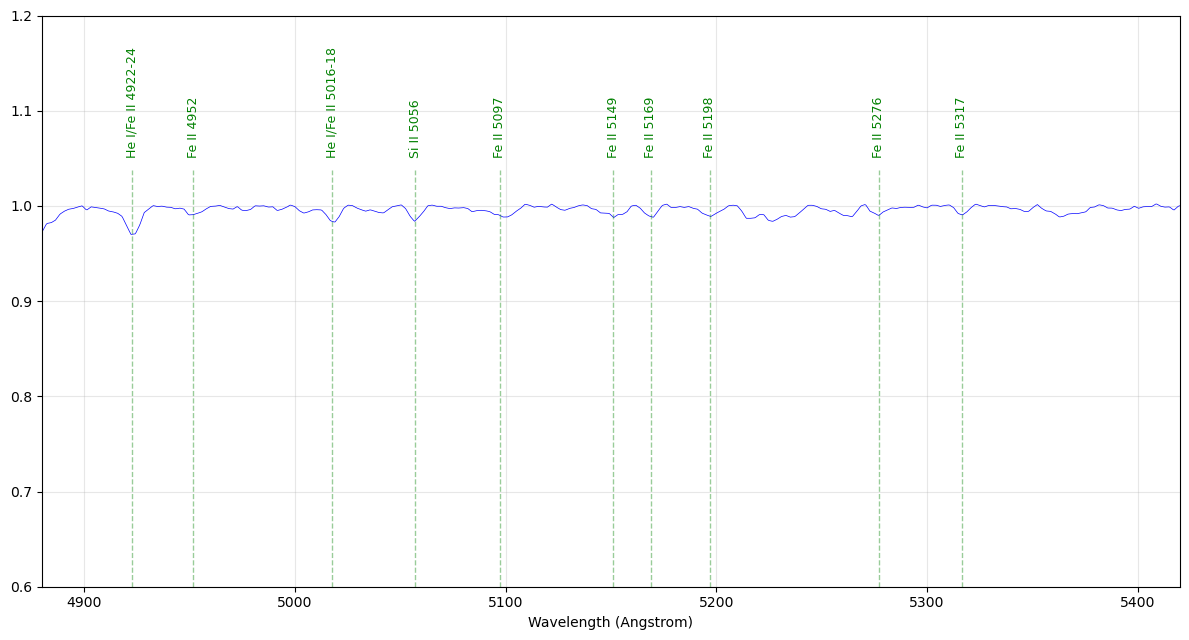

In [10]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (4880,5420), (0.60,1.20))

### Zoom  540 - 600 nm

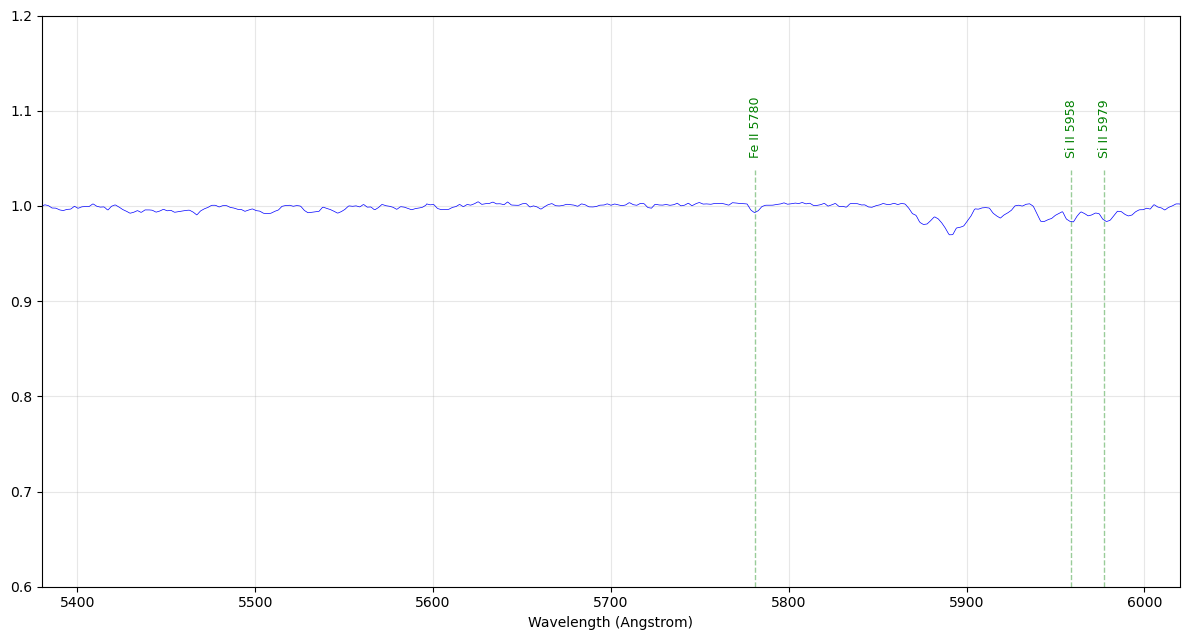

In [11]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (5380,6020), (0.60,1.20))

### Zoom  600 - 670 nm

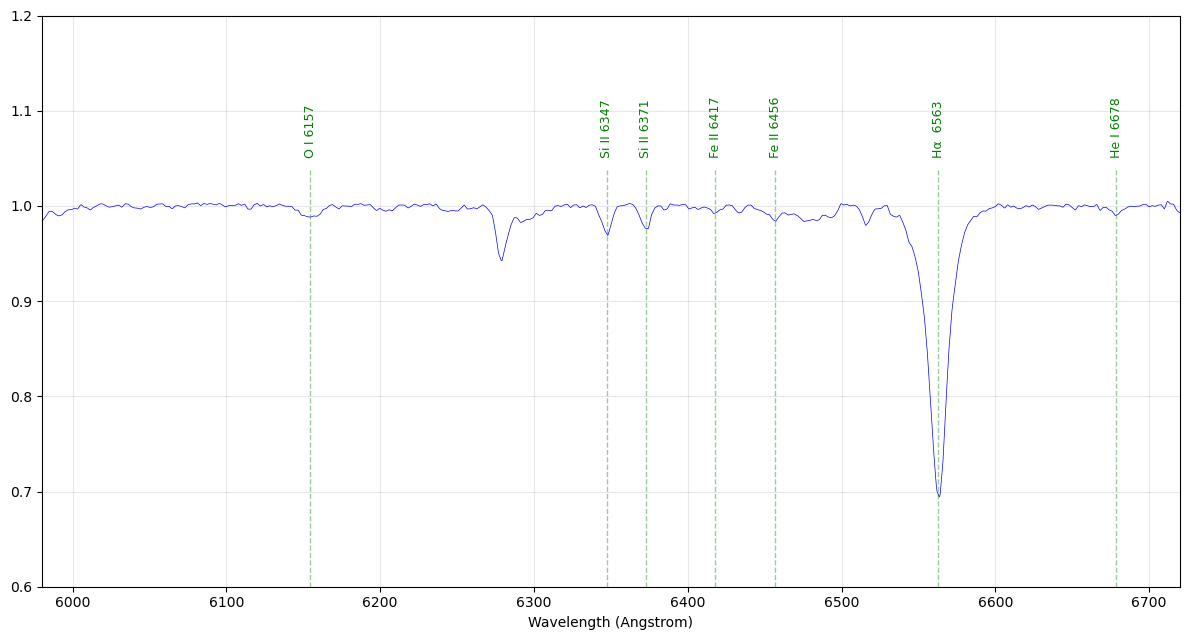

In [12]:
spec.plot_with_lines(wavelength, flux, spectral_lines_all, (5980,6720), (0.60,1.20))

## Line Measures

In [13]:
final_results = pd.read_csv("line_measured_atlas_20260111.csv")

In [14]:
def round_measurement(value, error):
    exponent = math.floor(math.log10(error))
    first_digit = int(error / (10 ** exponent))

    sig_figs = 2 if first_digit in (1,2) else 1

    decimals = sig_figs - exponent - 1

    value_rounded = round (value, decimals)
    error_rounded = round(error, decimals)

    return value_rounded, error_rounded

In [15]:
final_results = final_results[final_results["line_name"].apply(lambda s: not s.lower().startswith("unknown"))]

# Relative errors (%)
for col in ["wavelength", "ew", "fwhm", "intensity"]:
    final_results["rel_err_" + col] = 100 * final_results["delta_" + col] / final_results[col].abs()

# Approximate values and errors consistently 
for col in ["wavelength", "ew", "fwhm", "intensity"]:
    rounded = [round_measurement(v, e) for v, e in zip(final_results[col], final_results["delta_" + col])]
    final_results[col] = [r[0] for r in rounded]
    final_results["delta_" + col] = [r[1] for r in rounded]
    # relative error in %, 2 significant figures
    final_results["rel_err_" + col] = final_results["rel_err_" + col].apply(
        lambda x: float(f"{x:.2g}"))

final_results = final_results[["line_name",
    "wavelength", "delta_wavelength", "rel_err_wavelength",
    "ew", "delta_ew", "rel_err_ew",
    "fwhm", "delta_fwhm", "rel_err_fwhm",
    "intensity", "delta_intensity", "rel_err_intensity"]]

# Readable column names
final_results = final_results.rename(columns={
    "line_name": "Line",
    "wavelength": "Wavelength (Å)",
    "delta_wavelength": "Wavelength error (Å)",
    "rel_err_wavelength": "Wavelength rel. error (%)",
    "ew": "EW (Å)",
    "delta_ew": "EW error (Å)",
    "rel_err_ew": "EW rel. error (%)",
    "fwhm": "FWHM (Å)",
    "delta_fwhm": "FWHM error (Å)",
    "rel_err_fwhm": "FWHM rel. error (%)",
    "intensity": "Intensity",
    "delta_intensity": "Intensity error",
    "rel_err_intensity": "Intensity rel. error (%)",
})


In [16]:
# ---------- Formatting helpers ----------
def decimals_from_error(err):
    """Decimals to show, following the round_measurement rule:
    2 significant figures if the error starts with 1 or 2, otherwise 1."""
    exponent = math.floor(math.log10(err))
    first_digit = int(err / 10 ** exponent)
    sig_figs = 2 if first_digit in (1, 2) else 1
    return max(sig_figs - exponent - 1, 0)

def fmt_rel(x):
    """Relative error in %, 2 significant figures, never in scientific notation."""
    if x == 0:
        return "0"
    exp = math.floor(math.log10(abs(x)))
    r = round(x, 1 - exp)                       # round to 2 significant figures
    exp = math.floor(math.log10(abs(r)))        # rounding can raise the exponent (99.6 -> 100)
    return f"{r:.{max(1 - exp, 0)}f}"

# ---------- Find the columns of each group ----------
prefixes = ["Wavelength", "EW", "FWHM", "Intensity"]

def find_cols(prefix):
    cols = [c for c in final_results.columns if c.startswith(prefix)]
    rel = [c for c in cols if "rel" in c.lower()]
    err = [c for c in cols if "error" in c.lower() and c not in rel]
    val = [c for c in cols if c not in rel and c not in err]
    assert len(val) == len(err) == len(rel) == 1, \
        f"Unexpected columns for {prefix}: {cols}"
    return val[0], err[0], rel[0]

# ---------- Build a display copy (strings); final_results stays untouched ----------
display_df = final_results.copy()

for prefix in prefixes:
    val_col, err_col, rel_col = find_cols(prefix)
    decs = final_results[err_col].apply(decimals_from_error)
    display_df[val_col] = [f"{v:.{d}f}" for v, d in zip(final_results[val_col], decs)]
    display_df[err_col] = [f"{e:.{d}f}" for e, d in zip(final_results[err_col], decs)]
    display_df[rel_col] = final_results[rel_col].apply(fmt_rel)

# ---------- Colour the 4 groups of columns + row hover ----------
colors = {
    "Wavelength": "#dbeafe",   # light blue
    "EW":         "#dcfce7",   # light green
    "FWHM":       "#fef9c3",   # light yellow
    "Intensity":  "#fce7f3",   # light pink
}

table_styles = [
    {"selector": "th", "props": [("text-align", "center")]},
    # Row hover: darken every cell a bit, so each group keeps its own colour
    {"selector": "tr:hover td", "props": [("filter", "brightness(0.9)")]},
    # Uncoloured cells (Line column and index) get a light grey overlay instead
    {"selector": "tr:hover td.col0", "props": [("background-color", "rgba(128,128,128,0.15)")]},
    {"selector": "tr:hover th", "props": [("background-color", "rgba(128,128,128,0.15)")]},
]

# One CSS rule per column, using the column's position
for prefix, color in colors.items():
    for c in display_df.columns:
        if c.startswith(prefix):
            i = display_df.columns.get_loc(c)
            table_styles.append({
                "selector": f"td.col{i}",
                "props": [("background-color", color),
                          ("color", "black"),
                          ("text-align", "right")],
            })

styler = display_df.style.set_table_styles(table_styles)

styler

,Line,Wavelength (Å),Wavelength error (Å),Wavelength rel. error (%),EW (Å),EW error (Å),EW rel. error (%),FWHM (Å),FWHM error (Å),FWHM rel. error (%),Intensity,Intensity error,Intensity rel. error (%)
0,H alfa,6562.74,0.03,0.00049,6.90,0.30,4.4,14.89,0.14,0.96,-0.311,0.004,1.3
1,Si II 6371,6372.52,0.13,0.0020,0.211,0.016,7.8,7.7,0.5,6.0,-0.0259,0.0011,4.4
2,Si II 6347,6347.46,0.11,0.0017,0.218,0.012,5.7,7.10,0.30,4.5,-0.0289,0.0010,3.4
3,Si II 5056,5056.94,0.10,0.0020,0.080,0.013,16,5.3,0.5,8.9,-0.0141,0.0010,7.3
4,Si II 5041,5040.90,0.30,0.0062,0.044,0.019,43,6.3,1.6,25,-0.0064,0.0011,17
6,He I 4922,4922.95,0.09,0.0018,0.215,0.012,5.7,7.60,0.30,4.2,-0.0267,0.0005,1.9
7,H beta,4861.350,0.014,0.00030,7.31,0.22,3.0,13.247,0.013,0.10,-0.4189,0.0029,0.70
8,He I 4713,4713.6,0.4,0.0091,0.052,0.006,12,5.4,0.5,8.3,-0.0090,0.0007,7.8
10,Fe II 4489-91,4490.55,0.14,0.0030,0.019,0.006,31,3.4,0.4,13,-0.0052,0.0009,18
11,Mg II 4481,4481.69,0.03,0.00068,0.267,0.008,3.0,6.34,0.10,1.5,-0.0396,0.0008,1.9
